# Finite or infinite activity

**Jumps in financial time series, post 4 of 9**

> Pascal Lemieux is a quant with 15+ years across J.P. Morgan, RBC, Société Générale and First Abu Dhabi Bank, spanning structured products, derivatives pricing and volatility modelling. He now focuses on digital-asset derivatives: crypto options, volatility surfaces and hedging, including deep reinforcement learning for hedging and execution, work he began as co-founder of Affresco. M.Sc. Financial Mathematics, Bayes Business School.
>
> [LinkedIn](https://linkedin.com/in/pascal-lemieux) · [GitHub](https://github.com/PascalLemieux/jumps) · [The series](https://github.com/PascalLemieux/jumps#the-series)

This series tests what the jump literature claims against crypto market data, from 1-minute bars to tick trades. Every result is reproducible from the code in this repo. Every post asks the same question of a different effect: **is it real, or is it the measurement?**

| # | Post |
|:-:|------|
| 1 | [Most "jumps" are not jumps](01_jumps_vs_vol_bursts.ipynb) |
| 2 | [Intraday seasonality and false jumps](02_intraday_seasonality.ipynb) |
| 3 | [Bid-ask bounce and microstructure noise](03_microstructure_noise.ipynb) |
| **4** | **Finite or infinite activity** |
| 5 | [What jump activity does to your hedge](05_hedging_error.ipynb) |
| 6 | [Is volatility rough?](06_rough_volatility.ipynb) |
| 7 | Jumps or roughness in the smile? |
| 8 | The jump risk premium |
| 9 | Hedging with self-exciting jumps |

## The claim

The useful question about jumps is not "are there any" but "what kind". Rare and large, as in Merton's jump diffusion? Or an endless stream of small ones, as in variance gamma and CGMY, where the price is made of nothing else? The literature has a number for this, the jump activity index, and a well-known estimate of it: about 1.5 for large US stocks, which says "infinitely many small jumps".

I ran the same estimator on Bitcoin. Nine years of 1-minute bars, and one month of every trade for four coins.

- **It returns 3.** At every bar size from 1 second to 15 minutes, at every threshold from 5 to 10 standard deviations, for BTC, ETH, SOL and DOGE.
- **An activity index cannot exceed 2.** So this is not an index. The authors of the estimator say what a value above 2 means: the assumption behind it fails, and there may be no jumps to measure.
- **What it measures instead is the tail of returns**, which falls off like the cube of the threshold. That is an old stylised fact about returns, not a property of small jumps.
- **A clock test says the large moves are not jumps at all.** A jump of 20 basis points is a 20-basis-point return at every sampling frequency. BTC had 231 one-minute returns that large in October 2026. It had 12 one-second returns that large.

So for Bitcoin the answer to "finite or infinite activity" is that the question arrives too early. The large increments it is asked about are, for the most part, not jumps.

**Data.** Binance spot 1-minute klines for BTCUSDT and ETHUSDT, August 2017 to October 2026, and aggregated trades for BTC, ETH, SOL and DOGE in October 2026, all from the public archive. A small simulation checks that the estimator works when there is something to estimate.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jumps import activity as ac
from jumps import noise as nz
from jumps import plotting as jp
from jumps import seasonality as se
from jumps.data import load_klines

jp.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

ALPHAS = [5, 6, 7, 8, 10]      # lower thresholds, in local standard deviations
RATIO = 2.0                    # upper threshold = RATIO * lower threshold

def estimates(z):
    """Activity index estimates as 'value (standard error)' for each lower threshold."""
    return {f"alpha = {row['alpha']}": f"{row['beta']:.2f} ({row['se']:.2f})" for row in ac.index_table(z, ALPHAS, RATIO)}

## 1. The index, and how to estimate it

Write $\Delta X_s$ for the jump of the log price at time $s$. The **jump activity index**, the Blumenthal-Getoor index of the process, is

$$\beta = \inf\Big\{\, r \ge 0 \;:\; \sum_{s \le t} |\Delta X_s|^{r} < \infty \Big\}.$$

The sum of squared jumps is always finite, so $\beta \le 2$. The index says how violently the small jumps pile up:

| Process | Index |
|---|:-:|
| Compound Poisson, such as Merton's jumps | 0 |
| Variance gamma | 0 |
| CGMY, tempered stable | $Y$ |
| $\alpha$-stable | $\alpha$ |
| Brownian motion, as a limit | 2 |

Variance gamma has infinitely many jumps and still an index of 0, so the index alone does not separate finite from infinite activity. It measures how close the jump part is to a diffusion.

Aït-Sahalia and Jacod (2009) estimate it by counting. Let $U(\alpha)$ be the number of returns larger in absolute value than a threshold proportional to $\alpha$. If small jumps have index $\beta$, that count scales like $\alpha^{-\beta}$, so for two thresholds $\alpha < \alpha'$

$$\hat\beta = \frac{\log\big(U(\alpha)\,/\,U(\alpha')\big)}{\log(\alpha'/\alpha)}, \qquad \text{s.e.}(\hat\beta) = \frac{1}{\log(\alpha'/\alpha)}\sqrt{\frac{1}{U(\alpha')} - \frac{1}{U(\alpha)}}.$$

On a log-log plot of the count against the threshold, the slope is $-\beta$.

The thresholds have to sit well above what Brownian motion alone can produce. The authors put the lower one at 7 standard deviations of the continuous part and the upper one at twice that, on 5-second and 15-second returns of Intel and Microsoft in 2006, and found 1.4 to 1.8, which they summarise as about 1.5 and 1.6.

Here the unit is the *local* standard deviation. Crypto volatility changes several-fold from one regime to the next, so a fixed threshold would be 7 standard deviations one month and 2 the next. Each return is divided by the weekly seasonality factor of post 2 and by the bipower volatility of the returns before it, and thresholds are in those units: $\alpha$ from 5 to 10, $\alpha' = 2\alpha$.

### Does the estimator work? A sanity check

Four simulated series of three million increments, each a unit-variance Gaussian plus something:

- **Stable jumps**, index 1.5: infinitely active, the case the estimator is built for.
- **Poisson jumps**, rare and large: finite activity, index 0.
- **Bursts, no jumps**: volatility spikes and decays over a dozen increments. The path is continuous.
- **Plain diffusion.**

In [2]:
N_SIM = 3_000_000
worlds = {
    "Stable jumps, index 1.5": ac.simulate_increments("stable", N_SIM, alpha=1.5, seed=3),
    "Poisson jumps, index 0": ac.simulate_increments("poisson", N_SIM, seed=3),
    "Bursts, no jumps": ac.simulate_increments("bursts", N_SIM, burst_tail=2.5, bursts_per_10k=16.0, seed=3),
    "Plain diffusion": ac.simulate_increments("diffusion", N_SIM, seed=3),
}
sim_z = {name: x / se.local_volatility(pd.Series(x), 603).to_numpy() for name, x in worlds.items()}
sanity = pd.DataFrame({name: estimates(z) for name, z in sim_z.items()}).T
sanity["Returns above 5 sd, per million"] = [
    round(1e6 * ac.exceedance_counts(z, np.array([5.0]))[0] / np.isfinite(z).sum()) for z in sim_z.values()]
sanity

,alpha = 5,alpha = 6,alpha = 7,alpha = 8,alpha = 10,"Returns above 5 sd, per million"
"Stable jumps, index 1.5",1.57 (0.02),1.55 (0.02),1.53 (0.03),1.54 (0.03),1.55 (0.04),3150
"Poisson jumps, index 0",0.59 (0.03),0.73 (0.04),0.87 (0.04),1.06 (0.05),1.49 (0.07),381
"Bursts, no jumps",3.62 (0.11),3.42 (0.15),3.24 (0.19),3.47 (0.26),3.94 (0.44),633
Plain diffusion,nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),2


The estimator does its job. On the stable process it returns 1.53 to 1.57 for a true value of 1.5, at every threshold. On Poisson jumps it returns no stable number: the estimate climbs from 0.6 to 1.5 as the threshold moves, which is what "no power law in the small jumps" looks like. On the plain diffusion there is nothing above 5 standard deviations to count.

The third row is the one to remember. A path with no jumps at all, only volatility bursts, produces estimates between 3.2 and 3.9. Above 2.

## 2. Bitcoin and Ether, nine years of bars

In [3]:
START, END = "2017-08", "2026-10"
BREAKS = ["2021-01-01", "2024-01-01"]
close = {s: load_klines(s, START, END)["close"] for s in ["BTCUSDT", "ETHUSDT"]}

bar_z = {(s[:3], m): se.standardised_returns(close[s], m, BREAKS).to_numpy()
         for s in close for m in (1, 5, 15)}
rows = {}
for (coin, minutes), z in bar_z.items():
    rows[(coin, f"{minutes}-minute bars")] = estimates(z) | {
        "Returns": f"{np.isfinite(z).sum():,}",
        "Above 5 sd": f"{ac.exceedance_counts(z, np.array([5.0]))[0]:,}"}
pd.DataFrame(rows).T

BTCUSDT 1m: 111 months loaded


ETHUSDT 1m: 111 months loaded


alpha = 5    alpha = 6    alpha = 7    alpha = 8   alpha = 10    Returns Above 5 sd
BTC 1-minute bars   2.98 (0.03)  2.92 (0.04)  2.88 (0.05)  2.89 (0.06)  3.04 (0.08)  4,795,370     17,229
    5-minute bars   2.80 (0.06)  2.80 (0.07)  2.85 (0.09)  2.82 (0.11)  2.64 (0.14)    957,588      3,851
    15-minute bars  2.72 (0.09)  2.78 (0.12)  2.75 (0.14)  2.89 (0.18)  3.12 (0.26)    318,835      1,548
ETH 1-minute bars   3.02 (0.03)  2.96 (0.04)  2.93 (0.05)  2.89 (0.06)  3.02 (0.08)  4,795,369     16,922
    5-minute bars   2.97 (0.06)  2.89 (0.08)  2.79 (0.09)  2.77 (0.11)  2.77 (0.16)    957,587      3,836
    15-minute bars  2.92 (0.10)  2.90 (0.12)  2.97 (0.15)  3.13 (0.20)  3.31 (0.31)    318,835      1,502

Between 2.6 and 3.3 everywhere, and 2.9 to 3.0 on the 1-minute bars where the sample is largest. The standard errors are a few hundredths: on BTC at 1 minute the estimate sits more than thirty standard errors above 2.

Seventeen thousand of the 4.8 million one-minute returns exceed 5 local standard deviations. A Gaussian would produce three.

## 3. Four coins, every trade, down to one second

Maybe bars are too coarse and the small jumps live below them. The authors of the estimator used 5 and 15 seconds. October 2026, previous-tick prices on 1, 5 and 15-second clocks, for the four liquid coins of post 3. The local scale is the bipower volatility of the previous 603 one-minute returns, scaled to each clock by the square root of time, so every clock uses the same ruler and none depends on its own zero returns. No seasonal adjustment here: on the bars above it moves the estimates by 0.02.

In [4]:
COINS = ["BTC", "ETH", "SOL", "DOGE"]
TICK_START, TICK_END = "2026-10-01", "2026-10-31"
CLOCKS = [1, 5, 15, 60]

prices = {c: nz.clock_prices(f"{c}USDT", TICK_START, TICK_END, CLOCKS) for c in COINS}
clock_z = {(c, s): ac.standardise_clock(prices[c], s) for c in COINS for s in (1, 5, 15)}
rows = {}
for (coin, seconds), z in clock_z.items():
    rows[(coin, f"{seconds}-second clock")] = estimates(z) | {
        "Returns": f"{np.isfinite(z).sum():,}",
        "Above 5 sd": f"{ac.exceedance_counts(z, np.array([5.0]))[0]:,}"}
pd.DataFrame(rows).T

alpha = 5    alpha = 6    alpha = 7    alpha = 8   alpha = 10    Returns Above 5 sd
BTC  1-second clock   2.89 (0.03)  3.00 (0.04)  3.11 (0.06)  3.13 (0.07)  3.15 (0.10)  2,645,880     12,374
     5-second clock   3.36 (0.09)  3.45 (0.13)  3.36 (0.16)  3.26 (0.19)  3.32 (0.29)    529,176      2,358
     15-second clock  3.36 (0.16)  3.31 (0.21)  3.54 (0.30)  3.43 (0.37)  3.91 (0.62)    176,392        772
ETH  1-second clock   2.94 (0.03)  2.90 (0.04)  2.89 (0.05)  2.90 (0.07)  2.85 (0.09)  2,645,880     12,114
     5-second clock   2.78 (0.08)  2.81 (0.10)  2.83 (0.13)  2.87 (0.16)  2.80 (0.20)    529,176      2,064
     15-second clock  2.79 (0.13)  2.61 (0.16)  2.59 (0.20)  2.55 (0.24)  2.91 (0.37)    176,392        678
SOL  1-second clock   3.29 (0.04)  3.21 (0.05)  3.08 (0.07)  3.10 (0.08)  3.05 (0.11)  2,645,880     11,427
     5-second clock   3.16 (0.10)  3.24 (0.14)  3.46 (0.19)  3.58 (0.24)  3.77 (0.37)    529,176      1,710
     15-second clock  3.18 (0.17)  3.41 (0.26)  3.58 (0.35)  3.37 (0.40)  3.61 (0.62)    176,392        554
DOGE 1-second clock   3.33 (0.04)  3.10 (0.05)  2.90 (0.06)  2.77 (0.07)  2.62 (0.09)  2,645,880     13,703
     5-second clock   3.03 (0.09)  2.93 (0.12)  3.20 (0.16)  3.05 (0.18)  3.08 (0.26)    529,176      1,865
     15-second clock  2.95 (0.15)  2.78 (0.19)  2.88 (0.25)  2.91 (0.30)  2.79 (0.40)    176,392        586

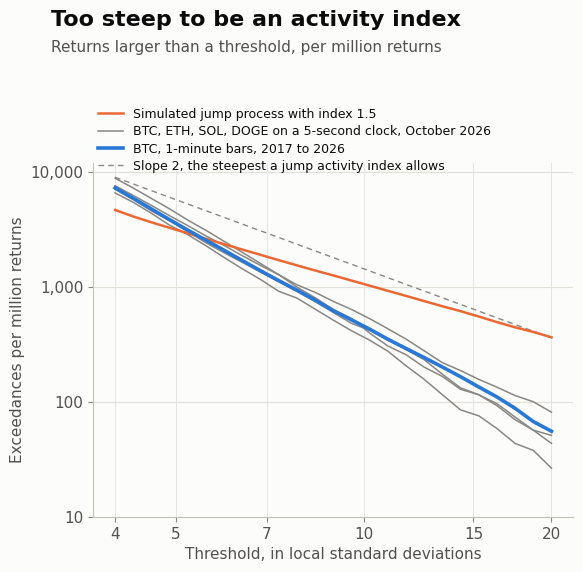

In [5]:
thresholds = np.geomspace(4, 20, 25)

def per_million(z):
    return 1e6 * ac.exceedance_counts(z, thresholds) / np.isfinite(z).sum()

series = [{"name": "Simulated jump process with index 1.5", "x": thresholds,
           "y": per_million(sim_z["Stable jumps, index 1.5"]), "color": jp.ORANGE, "lw": 1.8}]
series += [{"name": "BTC, ETH, SOL, DOGE on a 5-second clock, October 2026", "x": thresholds,
            "y": per_million(clock_z[(c, 5)]), "color": jp.MUTED, "lw": 1.1, "zorder": 2} for c in COINS]
series.append({"name": "BTC, 1-minute bars, 2017 to 2026", "x": thresholds,
               "y": per_million(bar_z[("BTC", 1)]), "color": jp.BLUE, "lw": 2.6, "zorder": 4})
fig = jp.tail_plot(
    series,
    title="Too steep to be an activity index",
    subtitle="Returns larger than a threshold, per million returns",
    xlabel="Threshold, in local standard deviations",
    ylabel="Exceedances per million returns",
    guides=[{"slope": -2.0, "x0": 4.0, "y0": 9000.0, "x1": 20.0,
             "text": "Slope 2, the steepest a jump activity index allows"}],
    xticks=[4, 5, 7, 10, 15, 20], yticks=[10, 100, 1000, 10000],
)
jp.save(fig, "04_exceedances");

Sixty estimates across four coins, three clocks and five thresholds. The lowest is 2.55, the highest 3.91. None is below 2, and the well-measured ones are near 3. Finer clocks do not uncover a hidden population of small jumps: at one second the estimate for BTC is 2.9 to 3.2.

On the chart the five empirical curves lie on top of each other, across coins, across clocks from 5 seconds to 1 minute, across one month and nine years. All are steeper than the dashed line, the slope a diffusion-like jump process would give at the very limit. The orange line is what an index of 1.5 looks like.

## 4. Three is not an index

The estimator's authors anticipate this. Their Remark 6: the estimates "may take a value bigger than or equal to 2", in which case "the estimation is not reliable", and it may indicate that the assumption behind the method fails, "which would be the case for example if there is no jump at all in the observed path".

What a slope of 3 does describe is known under another name. The tails of returns over short horizons fall off like a power of about 3, the inverse cubic law that Gopikrishnan, Meyer, Amaral and Stanley documented on US stocks in 1998. It is a statement about how often returns are *large*. The activity index is a statement about how the *small* jumps accumulate. The counting estimator can only tell them apart if the thresholds reach down into a regime where small jumps dominate and Brownian motion does not. For these coins, at these clocks, there is no such regime: the cubic tail starts where the Gaussian core ends, at 4 to 5 standard deviations, and runs to 20 without a kink.

A cubic tail could still be the size distribution of rare jumps. The next test separates that from the alternative.

## 5. The clock test

A jump is instantaneous. If the price jumps by 20 basis points, the return that contains the jump is about 20 basis points whether you sample every minute or every second. So the number of returns above a fixed absolute size should be the same at every clock, once the clock is fine enough that Brownian motion cannot reach that size.

A move that takes time behaves differently. Twenty basis points spread over 40 seconds is one large 1-minute return and no large 1-second return.

For each coin, take the level that is 5 standard deviations of a 1-minute return, about 20 basis points for BTC, and count the returns above it at each clock.

,Level (bps),1m,15s,5s,1s,1s as % of 1m
BTC,20.2,231,79,29,12,5
ETH,28.4,242,109,71,27,11
SOL,33.7,191,69,32,11,6
DOGE,36.7,206,103,60,31,15


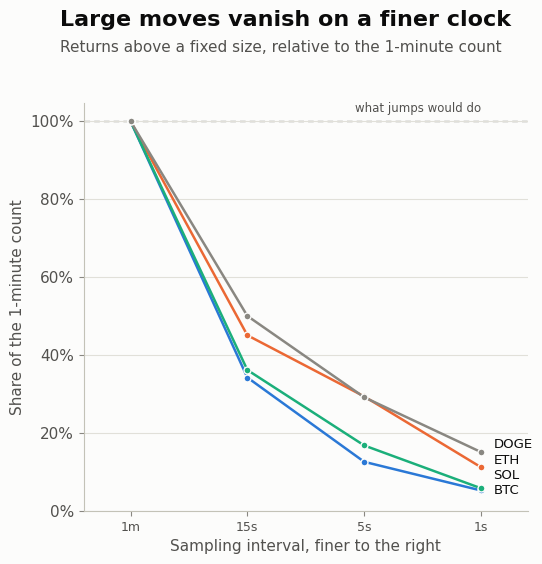

In [6]:
clock_labels = {60: "1m", 15: "15s", 5: "5s", 1: "1s"}
counts, levels = {}, {}
for c in COINS:
    r_minute = np.diff(prices[c][60])
    level = 5 * np.nanmedian(se.local_volatility(pd.Series(r_minute), 603))
    levels[c] = 1e4 * level
    counts[c] = {clock_labels[s]: int((np.abs(np.diff(prices[c][s])) > level).sum()) for s in clock_labels}
clock_table = pd.DataFrame(counts).T
clock_table.insert(0, "Level (bps)", pd.Series(levels).round(1))
clock_table["1s as % of 1m"] = (100 * clock_table["1s"] / clock_table["1m"]).round(0).astype(int)

fig = jp.signature_plot(
    [{"name": c, "y": [100 * counts[c][k] / counts[c]["1m"] for k in clock_labels.values()],
      "color": {"BTC": jp.BLUE, "ETH": jp.ORANGE, "SOL": jp.AQUA, "DOGE": jp.MUTED}[c]} for c in COINS],
    list(clock_labels.values()),
    title="Large moves vanish on a finer clock",
    subtitle="Returns above a fixed size, relative to the 1-minute count",
    ylabel="Share of the 1-minute count", xlabel="Sampling interval, finer to the right",
    reference=100.0, reference_label="what jumps would do", log=False, percent=True, ymin=0,
)
jp.save(fig, "04_clock_test")
clock_table

At a one-second clock only 5% to 15% as many returns clear the same bar. If the large one-minute returns were jumps, the lines would be flat at 100%.

The same thing seen from inside, in the manner of post 1: for every 1-minute return beyond 5 local standard deviations, how much of the move does its largest single second carry, and how many seconds does it take to cover half of it?

In [7]:
inside = pd.DataFrame({c: ac.inside_large_moves(prices[c], coarse=60, fine=1, sigmas=5.0) for c in COINS}).T
inside = pd.DataFrame({
    "1-minute moves beyond 5 sd": inside["moves"].astype(int),
    "Median size (bps)": (1e4 * inside["median_size"]).round(1),
    "Largest second, median share of the move (%)": (100 * inside["median_share"]).round(0).astype(int),
    "Moves where one second carries over 50%": inside["share_over_half"].astype(int),
    "Moves where one second carries over 80%": inside["share_over_80"].astype(int),
    "Seconds to cover half the move, median": inside["median_to_half"].astype(int),
})
inside

,1-minute moves beyond 5 sd,Median size (bps),"Largest second, median share of the move (%)",Moves where one second carries over 50%,Moves where one second carries over 80%,"Seconds to cover half the move, median"
BTC,209,22.5,25,24,4,29
ETH,201,36.1,27,36,8,29
SOL,151,39.9,22,14,2,28
DOGE,166,49.0,22,25,6,28


The four coins give the same answer. The largest second carries about a quarter of the move. Half the move takes 28 or 29 seconds, which is what a steady slide across the minute would take. Post 1 found this in the six largest 15-minute moves of Bitcoin's history. It holds one scale down, for a few hundred ordinary large moves in an ordinary month.

Some moves do look like a discontinuity: in BTC, 4 of 209 have one second carrying more than 80%. About one a week. Jumps exist. They are not what the tail is made of.

## 6. The companion test, and why I do not lean on it

Aït-Sahalia and Jacod (2011) test finite against infinite activity directly. With $B(p, u, \Delta) = \sum_i |r_i|^p\,\mathbf 1\{|r_i| \le u\}$ the sum of $p$-th powers of the returns no larger than a cutoff $u$, they compare two sampling intervals:

$$S = \frac{B(p, u, k\Delta)}{B(p, u, \Delta)} \;\longrightarrow\; \begin{cases} k^{\,p/2-1} & \text{finite activity, with a Brownian part,} \\ 1 & \text{infinite activity,} \end{cases} \qquad p > 2 .$$

With $p = 4$ and $k = 2$ the two limits are 2 and 1.

In [8]:
def s_statistic(r, scale):
    return {"cutoff 4 sd": ac.truncated_power_ratio(r, 4 * scale), "cutoff 7 sd": ac.truncated_power_ratio(r, 7 * scale)}

rows = {}
for c in COINS:
    for seconds in (5, 60):
        rows[(c, f"{seconds}-second clock")] = s_statistic(np.diff(prices[c][seconds]), ac.clock_scale(prices[c], seconds))
for name, x in worlds.items():
    rows[("Simulated", name)] = s_statistic(x, se.local_volatility(pd.Series(x), 603).to_numpy())
pd.DataFrame(rows).T.round(2)

cutoff 4 sd  cutoff 7 sd
BTC       5-second clock                  1.10         1.41
          60-second clock                 1.11         1.42
ETH       5-second clock                  1.08         1.30
          60-second clock                 1.21         1.06
SOL       5-second clock                  1.16         1.29
          60-second clock                 1.22         1.34
DOGE      5-second clock                  1.05         1.20
          60-second clock                 1.11         1.25
Simulated Stable jumps, index 1.5         1.55         1.48
          Poisson jumps, index 0          1.70         1.96
          Bursts, no jumps                1.50         1.62
          Plain diffusion                 1.69         2.00

On the simulated series the statistic behaves in the right order: close to 2 for the diffusion and the Poisson jumps, about 1.5 for the stable process, on its way to 1.

On the coins it reads 1.1 to 1.4, lower than the infinitely active simulation. Taken at face value: infinite activity.

I do not take it at face value, for two reasons. The same data give an "index" of 3 and, in post 3, a jump share of zero, and those cannot all hold for a process with infinitely active jumps. And the statistic, like the counting estimator, is a statement about increments at a finite clock. A truncated fourth-power sum is dominated by the returns just under the cutoff. When those belong to a power-law tail produced by volatility, their number grows more slowly with the sampling interval than a Gaussian's, and the ratio falls below 2 without any jump. My no-jump burst simulation brings it to 1.5 or 1.6, not to 1.1, so this is an argument and not a demonstration. The clock test is the only one of the three that asks the increments whether they are jumps.

## 7. What it changes

The handover for this post asked for more than a number. Here is what the evidence does to model choice.

**Pure-jump, infinitely active models** such as variance gamma and CGMY without a diffusion. As descriptions of the path, they predict a jump share near 100% at fine clocks (post 1's simulation) and an exceedance slope equal to an index below 2. BTC has a jump share near zero on pre-averaged ticks (post 3) and a slope of 3. As path models at these clocks, they are out. They can still fit option prices at a single maturity; that is a statement about one marginal distribution, not about how the price gets there.

**Jump diffusions with rare jumps**, Merton and its descendants. They need discontinuities to produce the tails. In October, of 209 one-minute moves beyond 5 standard deviations in BTC, 4 look like a discontinuity. Jumps are a real but minor ingredient, a few percent of variance at most.

**What the data ask for** is a continuous price whose volatility can multiply within a minute and whose own distribution is heavy-tailed. Whether that fast volatility component is "rough" is post 6.

**For a hedger** the distinction is practical. A true jump leaves a floor of risk under any delta hedge: no rebalancing frequency removes it. A move that takes 30 seconds to get half-way can in principle be followed, by someone who rebalances faster than that and can pay for it. How fast hedging error shrinks with rebalancing frequency on real Bitcoin paths, and what it costs, is post 5.

**For the short end of the smile**, if large price jumps are rare, steep short-dated smiles need another source. That is post 7.

## 8. Caveats

- **Thresholds are in local units.** The estimator was designed with thresholds proportional to a power of the sampling interval and a volatility updated occasionally. Standardising each return by its own local volatility is a practical necessity in crypto and a departure from the original design. The slope is not sensitive to the scale, since a constant error in the ruler shifts a power law without tilting it, but a ruler that lags volatility bursts is itself a source of heavy tails.
- **That is the point, and also the limit.** The estimate of 3 says the standardised returns have a cubic tail. It does not say why. The clock test says most of it is not jumps. Neither identifies the volatility process.
- **Noise.** Post 3 showed what tick data does to bipower variation. Here the finest clocks inherit their scale from 1-minute returns to avoid that, but previous-tick prices at 1 second are still lumpy, with half of all returns at zero for BTC.
- **One month of ticks.** The clock test and the inside-the-move table cover October 2026 only. The bar results cover nine years.
- **Small jumps below one second** are not ruled out. The claim is about the increments the estimator can see.
- **The stock benchmark is from 2006**, on transaction data whose returns have a standard deviation of 5 to 7 basis points per trade (the authors' Table 3). Post 3 showed what noise of that order does to tick-level statistics. Whether a re-run with noise-robust tools would still give 1.5 is an open question, and not one this notebook answers.

## 9. Takeaways

1. The jump activity estimator returns about 3 on Bitcoin, on every clock from 1 second to 15 minutes. The maximum for a jump process is 2.
2. It is measuring the cubic tail of returns, not the pile-up of small jumps. The same number appears for four coins, a month of ticks and nine years of bars.
3. Large moves are not instantaneous. A one-second clock finds 5% to 15% as many large returns as a one-minute clock, and the biggest second of a large one-minute move carries a quarter of it.
4. "Finite or infinite activity" presumes the large increments are jumps. For Bitcoin, mostly, they are not.
5. That rules out pure-jump models as path descriptions and leaves jump diffusions with little to do. The tail is in the volatility.

## Equation images for the post

In [9]:
jp.render_equation(r"\beta=\inf\{\,r\geq 0\ :\ \sum_{s\leq t}|\Delta X_s|^{r}<\infty\,\}", "04_eq_index",
                   "Jump activity index: how fast the small jumps pile up. Never above 2.", fontsize=22)
jp.render_equation(r"\hat{\beta}=\dfrac{\log\,(\,U(\alpha)\,/\,U(\alpha'))}{\log\,(\alpha'/\alpha)}", "04_eq_estimator",
                   "Count the returns above two thresholds. The slope is the index.", fontsize=24);

## References

- Aït-Sahalia, Y. and Jacod, J. (2009). Estimating the degree of activity of jumps in high frequency data. *Annals of Statistics*, 37(5A), 2202-2244. [arXiv:0908.3095](https://arxiv.org/abs/0908.3095)
- Aït-Sahalia, Y. and Jacod, J. (2011). Testing whether jumps have finite or infinite activity. *Annals of Statistics*, 39(3), 1689-1719. [arXiv:1211.5219](https://arxiv.org/abs/1211.5219)
- Gopikrishnan, P., Meyer, M., Amaral, L. A. N. and Stanley, H. E. (1998). Inverse cubic law for the probability distribution of stock price variations. [arXiv:cond-mat/9803374](https://arxiv.org/abs/cond-mat/9803374)

The estimator, its standard error, the truncated power statistic and the Intel and Microsoft estimates were checked against the arXiv texts of the first two papers.

---

*Code, data loaders and figures: [github.com/PascalLemieux/jumps](https://github.com/PascalLemieux/jumps). Comments and corrections welcome on [LinkedIn](https://linkedin.com/in/pascal-lemieux).*